<a href="https://colab.research.google.com/github/Rubin-S/nifty50-sma-backtester/blob/main/Dual_SMA_Strategy_vs_Buy_%26_Hold_(2018_present).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantitative Trading Strategy: Dual Moving Average Crossover on NIFTY 50
## Module 1: Environment Setup & Historical Data Ingestion

### Objective
Fetch daily historical price data for the benchmark index (**NIFTY 50**) to test a rule-based trend-following strategy.

* **Asset:** NIFTY 50 Index (`^NSEI`)
* **Timeframe:** 2018 to Present
* **Data Provider:** Yahoo Finance via `yfinance`

In [ ]:
# 1. Installing necessary library
!pip install yfinance -q

# 2. Import core quantitative analysis packages
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

# 3. Fetch daily adjusted data for NIFTY 50
ticker = "^NSEI"
df = yf.download(ticker, start="2018-01-01", auto_adjust=True)

# Clean multi-index headers if returned by yfinance
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

# Display the first 5 trading days
df.head()

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Date,,,,,
2018-01-02,10442.200195,10495.200195,10404.650391,10477.549805,153400
2018-01-03,10443.200195,10503.599609,10429.549805,10482.650391,167300
2018-01-04,10504.799805,10513.000000,10441.450195,10469.400391,174900
2018-01-05,10558.849609,10566.099609,10520.099609,10534.250000,180900
2018-01-08,10623.599609,10631.200195,10588.549805,10591.700195,169000


## Module 2: Feature Engineering (Dual Moving Averages)

### Objective
Construct trend-following indicators using Simple Moving Averages (SMA) based on closing prices.

* **Fast SMA (20-day):** Captures short-term price momentum 🏃.
* **Slow SMA (50-day):** Establishes the medium-term market baseline 🚶.

In [ ]:
# 1. Compute 20-day and 50-day rolling averages
df['SMA_Fast'] = df['Close'].rolling(window=20).mean()
df['SMA_Slow'] = df['Close'].rolling(window=50).mean()

# 2. Inspect the latest values
df[['Close', 'SMA_Fast', 'SMA_Slow']].tail()

Price,Close,SMA_Fast,SMA_Slow
Date,,,
2026-08-24,24219.050781,24381.692578,24193.951992
2026-08-25,24334.550781,24399.152637,24203.565000
2026-08-26,24207.750000,24397.030176,24207.936992
2026-08-27,24090.849609,24385.715137,24208.040000
2026-08-28,24175.650391,24375.317676,24208.193008


## Module 3: Signal Generation & Execution Lag

### Objective
Create trading rules based on moving average crossovers and lag trade execution by one day to prevent **look-ahead bias**.

* **Rule:** Long (1.0) when Fast SMA > Slow SMA; otherwise Cash (0.0).
* **Execution:** Trades execute on day $t+1$ using signals generated at the close of day $t$.

In [ ]:
# 1. Generate the raw signal (1.0 = Buy/Hold, 0.0 = Cash)
df['Raw_Signal'] = np.where(df['SMA_Fast'] > df['SMA_Slow'], 1.0, 0.0)

# 2. Shift the signal by 1 day so we execute on day t+1
df['Position'] = df['Raw_Signal'].shift(1).fillna(0.0)

# 3. Inspect recent signals and positions
df[['Close', 'SMA_Fast', 'SMA_Slow', 'Raw_Signal', 'Position']].tail()

Price,Close,SMA_Fast,SMA_Slow,Raw_Signal,Position
Date,,,,,
2026-08-24,24219.050781,24381.692578,24193.951992,1.0,1.0
2026-08-25,24334.550781,24399.152637,24203.565000,1.0,1.0
2026-08-26,24207.750000,24397.030176,24207.936992,1.0,1.0
2026-08-27,24090.849609,24385.715137,24208.040000,1.0,1.0
2026-08-28,24175.650391,24375.317676,24208.193008,1.0,1.0


## Module 4: Returns Calculation & Friction Modeling

### Objective
Calculate the daily strategy returns and subtract realistic execution friction (brokerage, STT, and slippage) on days when trades occur.

* **Market Return:** Daily percentage change of NIFTY 50 closing prices.
* **Trade Detection:** Identifying state changes ($0 \rightarrow 1$ or $1 \rightarrow 0$) using position differencing.
* **Friction Cost:** 5 basis points ($0.05\%$) deducted per trade transaction.

In [ ]:
# 1. Calculate benchmark market daily return
df['Market_Return'] = df['Close'].pct_change().fillna(0.0)

# 2. Identify trades (absolute change in position)
df['Trades'] = df['Position'].diff().abs().fillna(0.0)

# 3. Define transaction cost (5 bps = 0.05%)
fee_bps = 5
cost_per_trade = fee_bps / 10000.0

# 4. Net Strategy Return = Gross Return - Execution Friction
df['Strategy_Return'] = (df['Position'] * df['Market_Return']) - (df['Trades'] * cost_per_trade)

# 5. Inspect recent returns
df[['Close', 'Market_Return', 'Position', 'Trades', 'Strategy_Return']].tail()

Price,Close,Market_Return,Position,Trades,Strategy_Return
Date,,,,,
2026-08-24,24219.050781,-0.001359,1.0,0.0,-0.001359
2026-08-25,24334.550781,0.004769,1.0,0.0,0.004769
2026-08-26,24207.750000,-0.005211,1.0,0.0,-0.005211
2026-08-27,24090.849609,-0.004829,1.0,0.0,-0.004829
2026-08-28,24175.650391,0.003520,1.0,0.0,0.003520


## Module 5: Cumulative Equity Curves

### Objective
Track the growth of an initial ₹1 investment over time by compounding daily percentage returns for both the strategy and the benchmark.

* **Benchmark Equity:** $(1 + R_{market})$ compounded daily.
* **Strategy Equity:** $(1 + R_{strategy})$ compounded daily.

In [ ]:
# 1. Compute cumulative wealth growth starting from 1.0 (₹1 base)
df['Benchmark_Equity'] = (1 + df['Market_Return']).cumprod()
df['Strategy_Equity'] = (1 + df['Strategy_Return']).cumprod()

# 2. Inspect the latest cumulative equity values
df[['Close', 'Benchmark_Equity', 'Strategy_Equity']].tail()

Price,Close,Benchmark_Equity,Strategy_Equity
Date,,,
2026-08-24,24219.050781,2.319344,2.414689
2026-08-25,24334.550781,2.330405,2.426204
2026-08-26,24207.750000,2.318261,2.413562
2026-08-27,24090.849609,2.307066,2.401907
2026-08-28,24175.650391,2.315187,2.410362


## Module 6: Quantitative Risk & Performance Metrics

### Objective
Evaluate risk-adjusted performance using core quantitative metrics:

* **CAGR (Compound Annual Growth Rate):** Geometric annualized return.
* **Annualized Volatility:** Standard deviation of daily returns scaled to a 252-day trading year.
* **Sharpe Ratio:** Risk-adjusted return assuming a $0\%$ risk-free rate ($\frac{\text{CAGR}}{\text{Volatility}}$).
* **Maximum Drawdown (MDD):** The largest peak-to-trough decline before a new peak is reached.

In [ ]:
# 1. Trading days in a standard year
trading_days = 252
n_days = len(df)

# 2. CAGR (Compound Annual Growth Rate)
cagr_strat = (df['Strategy_Equity'].iloc[-1]) ** (trading_days / n_days) - 1
cagr_bench = (df['Benchmark_Equity'].iloc[-1]) ** (trading_days / n_days) - 1

# 3. Annualized Volatility (Risk)
vol_strat = df['Strategy_Return'].std() * np.sqrt(trading_days)
vol_bench = df['Market_Return'].std() * np.sqrt(trading_days)

# 4. Sharpe Ratio (assuming 0% risk-free rate for simplicity)
sharpe_strat = cagr_strat / vol_strat if vol_strat != 0 else 0
sharpe_bench = cagr_bench / vol_bench if vol_bench != 0 else 0

# 5. Maximum Drawdown (MDD)
rolling_max = df['Strategy_Equity'].cummax()
drawdown = (df['Strategy_Equity'] - rolling_max) / rolling_max
max_drawdown = drawdown.min()

# Benchmark Max Drawdown
bench_rolling_max = df['Benchmark_Equity'].cummax()
bench_drawdown = (df['Benchmark_Equity'] - bench_rolling_max) / bench_rolling_max
bench_max_drawdown = bench_drawdown.min()

# Print Summary Report
print("=== Performance & Risk Attribution Report ===")
print(f"Strategy CAGR:         {cagr_strat * 100:.2f}% | Benchmark: {cagr_bench * 100:.2f}%")
print(f"Annualized Volatility: {vol_strat * 100:.2f}% | Benchmark: {vol_bench * 100:.2f}%")
print(f"Sharpe Ratio:          {sharpe_strat:.2f}  | Benchmark: {sharpe_bench:.2f}")
print(f"Max Drawdown (MDD):    {max_drawdown * 100:.2f}% | Benchmark: {bench_max_drawdown * 100:.2f}%")

=== Performance & Risk Attribution Report ===
Strategy CAGR:         10.95% | Benchmark: 10.42%
Annualized Volatility: 11.01% | Benchmark: 16.92%
Sharpe Ratio:          0.99  | Benchmark: 0.62
Max Drawdown (MDD):    -20.17% | Benchmark: -38.44%


## Module 7: Equity Curve Visualization & Analysis

### Objective
Plot the compounded equity curves over time to visually compare how the Dual SMA Strategy navigated market regimes versus the Buy & Hold benchmark.

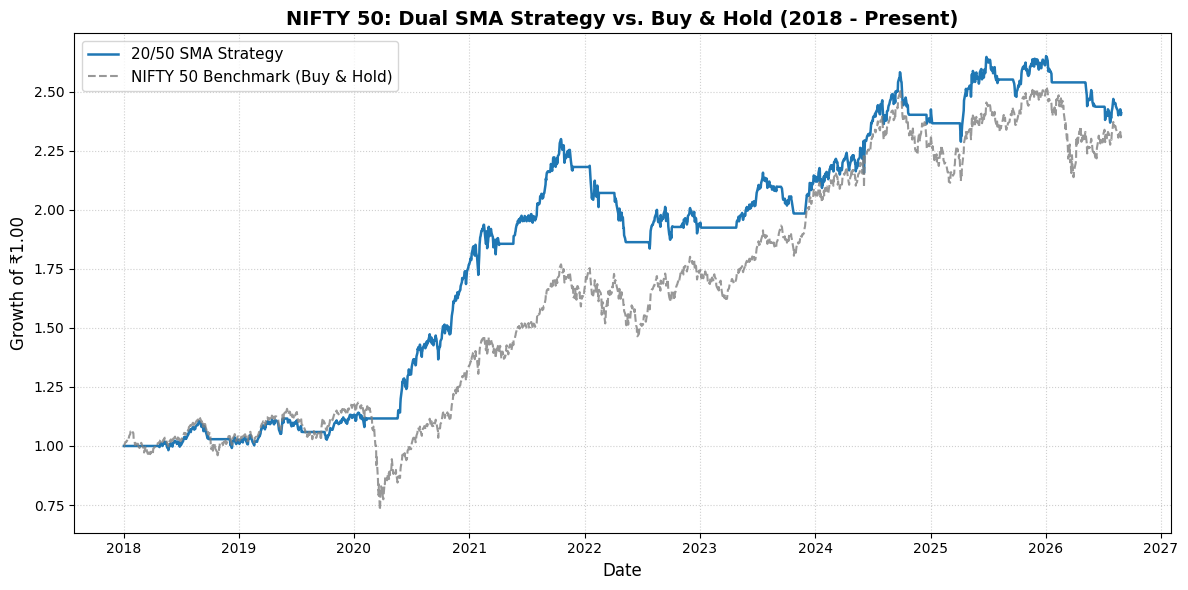

In [ ]:
# 1. Create figure and plot cumulative equity curves
plt.figure(figsize=(12, 6))

plt.plot(df.index, df['Strategy_Equity'], label='20/50 SMA Strategy', color='#1f77b4', linewidth=1.8)
plt.plot(df.index, df['Benchmark_Equity'], label='NIFTY 50 Benchmark (Buy & Hold)', color='#7f7f7f', linestyle='--', alpha=0.8)

# 2. Formatting the chart for presentation
plt.title('NIFTY 50: Dual SMA Strategy vs. Buy & Hold (2018 - Present)', fontsize=14, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Growth of ₹1.00', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()

# 3. Display plot
plt.show()